In [ ]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt

from climate_year_selection.helper_functions import build_df, process_all_hydro_files
from climate_year_selection.constants import (
    BASE_OUTPUT,
    BASE_INPUT,
    COUNTRIES,
    INPUT_DIR_HYDRO,
    MODELS,
    MODELS_FNAME,
    HYDRO_VARS,
)
from RUN_SETTINGS import (
    DF_DAILY_FNAME,
    DF_HOURLY_FNAME,
    DF_HYDRO_FNAME,
    DF_PROD_DEMAND_FNAME,
    DF_PROD_DEMAND_FNAME_REGION,
)

In [2]:
if not os.path.exists(DF_DAILY_FNAME):
    print("Calculating df_daily...")
    df_hourly, df_daily = build_df()
    df_hourly, df_daily = df_hourly.reset_index(), df_daily.reset_index()
    df_hourly.to_csv(DF_HOURLY_FNAME)
    df_daily.to_csv(DF_DAILY_FNAME)
    # df_daily["year"] = df_daily["Date"].dt.year
else:
    print("Taking df_daily from memory...")
    df_daily = pd.read_csv(DF_DAILY_FNAME, index_col=0)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])

# hydro
if not os.path.exists(DF_HYDRO_FNAME):
    print("Calculating hydro data...")
    # build individual hydro df's per model
    process_all_hydro_files()

    # aggregate all models and variables
    dfs_hydro_prod = []
    for model_fname, model_name in zip(MODELS_FNAME, MODELS):
        dfs_hydro_model = []
        for hydro_var in HYDRO_VARS:
            filename_hydro_agg = f"P_CMI6_{model_fname}_{hydro_var}_2016_2046_NUTS0.csv"
            dfs_hydro_model.append(
                pd.read_csv(
                    os.path.join(INPUT_DIR_HYDRO, filename_hydro_agg), index_col="Date"
                )
            )
        df_hydro_model = pd.concat(dfs_hydro_model, axis=1)
        df_hydro_model["model"] = model_name
        dfs_hydro_prod.append(df_hydro_model)

    df_hydro_prod = pd.concat(dfs_hydro_prod, axis=0)
    df_hydro_prod.to_parquet(DF_HYDRO_FNAME)
else:
    print("Taking hydro data from memory...")
    df_hydro_prod = pd.read_parquet(DF_HYDRO_FNAME)

df_daily.head()
df_hydro_prod.head()

Calculating df_daily...
Calculating hydro data...


,AL_HRO_prod,AT_HRO_prod,BE_HRO_prod,BA_HRO_prod,BG_HRO_prod,HR_HRO_prod,CZ_HRO_prod,DK_HRO_prod,EE_HRO_prod,EL_HRO_prod,...,RO_HPO_prod,RS_HPO_prod,SK_HPO_prod,SI_HPO_prod,ES_HPO_prod,SE_HPO_prod,CH_HPO_prod,UK_HPO_prod,TR_HPO_prod,model
Date,,,,,,,,,,,,,,,,,,,,,
2015-07-20 00:00:00,0.017734,2.176087,0.004644,0.003453,0.140959,0.189031,0.11252,NaN,NaN,0.017601,...,NaN,NaN,0.080631,0.355013,NaN,NaN,NaN,NaN,NaN,cmcc_cm2_sr5
2015-07-20 01:00:00,0.017734,2.176087,0.004644,0.003453,0.140959,0.189031,0.11252,NaN,NaN,0.017601,...,NaN,NaN,0.080631,0.355013,NaN,NaN,NaN,NaN,NaN,cmcc_cm2_sr5
2015-07-20 02:00:00,0.017734,2.176087,0.004644,0.003453,0.140959,0.189031,0.11252,NaN,NaN,0.017601,...,NaN,NaN,0.080631,0.355013,NaN,NaN,NaN,NaN,NaN,cmcc_cm2_sr5
2015-07-20 03:00:00,0.017734,2.176087,0.004644,0.003453,0.140959,0.189031,0.11252,NaN,NaN,0.017601,...,NaN,NaN,0.080631,0.355013,NaN,NaN,NaN,NaN,NaN,cmcc_cm2_sr5
2015-07-20 04:00:00,0.017734,2.176087,0.004644,0.003453,0.140959,0.189031,0.11252,NaN,NaN,0.017601,...,NaN,NaN,0.080631,0.355013,NaN,NaN,NaN,NaN,NaN,cmcc_cm2_sr5


In [3]:
df_hydro_prod = df_hydro_prod.reset_index()
df_hydro_prod["Date"] = pd.to_datetime(df_hydro_prod["Date"])

df_hydro_prod_daily = (
    df_hydro_prod.groupby(["model", pd.Grouper(key="Date", freq="D")])
    .sum(numeric_only=True)
    .reset_index()
    .sort_values(["model", "Date"])
)

In [4]:
# get capacities from ERAA2024 excel file

df_caps = pd.read_excel(
    "/net/pc230050/nobackup/users/duinen/04_weather_year_selection/inputs/ERAA2024_GenerationCapacities.xlsx"
)


def compute_capacities(
    df_caps: pd.DataFrame,
    technologies: list[str],
    year: int = 2030,
    countries: list[str] | None = None,
) -> dict:
    """
    Compute GW capacities per country and technology by aggregating
    all bidding zones belonging to the same country.
    """
    df = df_caps.copy()
    df["COUNTRY"] = df["MARKET_NODE"].str[:2]

    # replace country == 'GR' with 'EL'
    df.loc[df["COUNTRY"] == "GR", "COUNTRY"] = "EL"

    # reduce full dataframe to relevant entries
    df = df[
        (df["TARGET_YEAR"] == year)
        & (df["DATA_VERSION"] == "Final")
        & (df["TECHNOLOGY"].isin(technologies))
    ]

    if countries is not None:
        df = df[df["COUNTRY"].isin(countries)]

    cap = (
        df.groupby(["COUNTRY", "TECHNOLOGY"])["CAPACITY_MW"]
        .sum()
        .div(1000)
        .unstack("TECHNOLOGY")
        .fillna(0.0)
    )

    return cap.to_dict(orient="index")


country_caps = compute_capacities(
    df_caps,
    technologies=["Wind offshore", "Wind onshore", "Solar (PV)"],
    countries=COUNTRIES,
)

pd.DataFrame(country_caps).T.to_csv(
    os.path.join(BASE_INPUT, "country_generation_capacities_2030.csv")
)

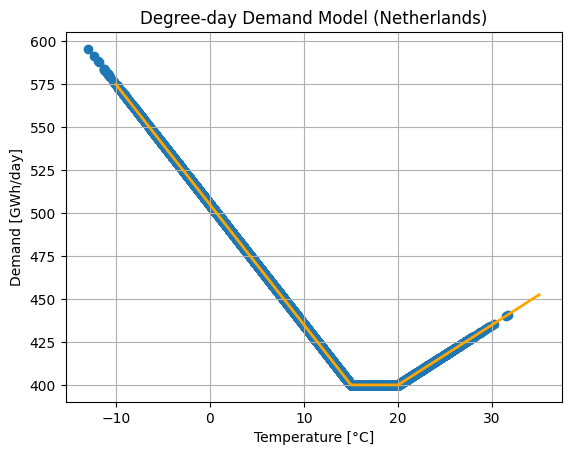

In [ ]:
# fit a VERY coarse demand-temp model
# Scale other countries according to annual demand ratio


def demand_model(T: np.ndarray) -> np.ndarray:
    """
    Estimate electricity demand [GWh/day] as a function of temperature [°C].
    """
    # Base parameters tuned to match plot visually
    a = 400  # baseline demand at mild temps
    b = 7  # heating slope [GWh/day per °C below T_heat]
    c = 3.5  # cooling slope [GWh/day per °C above T_cool]
    T_heat = 15
    T_cool = 20

    heating_term = np.maximum(0, T_heat - T)
    cooling_term = np.maximum(0, T - T_cool)

    return a + b * heating_term + c * cooling_term


T_range = np.linspace(-10, 35, 300)
plt.plot(T_range, demand_model(T_range), color="orange", lw=2)
plt.scatter(df_daily["NL_TEMP"].values, demand_model(df_daily["NL_TEMP"].values))
plt.xlabel("Temperature [°C]")
plt.ylabel("Demand [GWh/day]")
plt.title("Degree-day Demand Model (Netherlands)")
plt.grid(True)
plt.show()


In [6]:
df_annual_demand = pd.read_excel(
    "/net/pc230050/nobackup/users/duinen/04_weather_year_selection/inputs/ERAA2024_Aggregated_Demand.xlsx"
)


def compute_annual_demand_ratio(
    df_annual_demand: pd.DataFrame, target_year: int = 2030
) -> pd.DataFrame:
    """
    Compute annual demand ratios per country relative to NL for a given target year.
    """
    df_demand_ratio = df_annual_demand.copy()
    df_demand_ratio["COUNTRY"] = df_demand_ratio["MARKET_NODE"].str[:2]
    # replace country == 'GR' with 'EL'
    df_demand_ratio.loc[df_demand_ratio["COUNTRY"] == "GR", "COUNTRY"] = "EL"
    df_demand_ratio = df_demand_ratio[
        (df_demand_ratio["TARGET_YEAR"] == target_year)
        & (df_demand_ratio["DATA_VERSION"] == "Final")
        & (df_demand_ratio["TYPE_WS"] == "Avg")
    ]
    demand_nl = df_demand_ratio[df_demand_ratio["COUNTRY"] == "NL"][
        "DEMAND_TWH"
    ].values[0]
    df_demand_ratio["DEMAND_RATIO"] = df_demand_ratio["DEMAND_TWH"] / demand_nl
    demand_ratio_dict = (
        df_demand_ratio.set_index("COUNTRY")
        .groupby("COUNTRY")["DEMAND_RATIO"]
        .sum()
        .to_dict()
    )
    return demand_ratio_dict


demand_ratio_dict = compute_annual_demand_ratio(df_annual_demand)

/usr/people/duinen/04_weather_year_selection/weather_year_selection/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [ ]:
# build production and demand dataframe from daily capacity factors and temperature

# base frame
base_cols = ["model", "Date", "Hydrological_year", "Calendar_year"]
df_prod_demand = df_daily[base_cols].merge(
    df_hydro_prod_daily,
    on=["model", "Date"],
    how="left",
)

prod_cols = {}

for country in COUNTRIES:
    # first prepary columns in dict, then concat at once
    # multiply by 24 because df_daily has daily averages (e.g. GW to GWh/day)
    off_cap = country_caps[country]["Wind offshore"] * 24
    on_cap = country_caps[country]["Wind onshore"] * 24
    sol_cap = country_caps[country]["Solar (PV)"] * 24

    off_prod = df_daily[f"{country}_OFF"] * off_cap
    on_prod = df_daily[f"{country}_ON"] * on_cap
    sol_prod = df_daily[f"{country}_SOLAR"] * sol_cap

    hydro_prod = (
        df_prod_demand[f"{country}_HRO_prod"]
        + df_prod_demand[f"{country}_HRG_prod"]
        + df_prod_demand[f"{country}_HPO_prod"]
    )

    # scale demand according to annual ratio
    demand = (
        demand_model(df_daily[f"{country}_TEMP"].to_numpy())
        * demand_ratio_dict[country]
    )
    demand = pd.Series(demand, index=df_daily.index)

    prod_cols[f"{country}_OFF_prod"] = off_prod
    prod_cols[f"{country}_ON_prod"] = on_prod
    prod_cols[f"{country}_SOLAR_prod"] = sol_prod
    prod_cols[f"{country}_Demand"] = demand

    prod_cols[f"{country}_Residual_load"] = (
        demand.fillna(0)
        - off_prod.fillna(0)
        - on_prod.fillna(0)
        - sol_prod.fillna(0)
        - hydro_prod.fillna(0)
    )

df_prod_demand = pd.concat(
    [df_prod_demand, pd.DataFrame(prod_cols, index=df_daily.index)], axis=1
)


In [8]:
df_prod_demand.to_parquet(DF_PROD_DEMAND_FNAME)

In [ ]:
# also, sum by region. For possible optimisation per region instead of per country.
regions = {
    "Northwest": ["NL", "BE", "FR", "DE", "LU", "DK"],
    "UK_IE": ["UK", "IE"],
    "Iberia": ["ES", "PT"],
    "Central": ["AT", "CH", "IT", "MT"],
    "Baltic": ["EE", "LV", "LT", "NO", "SE", "FI"],
    "East": ["PL", "CZ", "SK", "HU", "HR", "SI"],
    "Southeast": ["BA", "RS", "RO", "MK", "AL", "ME", "BG", "TR", "EL"],
}

In [11]:
df = df_prod_demand.copy()

region_cols_created = []

for region, countries in regions.items():
    region_country_cols = [
        col
        for col in df.columns
        if any(col.startswith(f"{country}_") for country in countries)
    ]

    suffixes = {col.split("_", 1)[1] for col in region_country_cols}

    for suffix in suffixes:
        cols_to_sum = [
            col for col in region_country_cols if col.split("_", 1)[1] == suffix
        ]
        new_col = f"{region}_{suffix}"
        df[new_col] = df[cols_to_sum].sum(axis=1)
        region_cols_created.append(new_col)

meta_cols = ["model", "Date", "Hydrological_year"]

df_region = df[meta_cols + sorted(region_cols_created)]

df_region.to_parquet(DF_PROD_DEMAND_FNAME_REGION)